# 01 — Exploratory data analysis

**Question.** Can we predict which Halifax Transit routes and time periods will have buses passing up riders
(a *passenger overload*), and does weather improve that beyond past ridership?

Inputs (built by `src/load.py` and `src/build_panel.py`):
- `data/processed/overloads.parquet` — one row per bus overload incident (Halifax local time, ferry + out-of-area removed)
- `data/processed/apc.parquet` — half-hourly APC boardings 2017-10 → 2026-11 (counter glitches set to NaN)
- `data/processed/panel.parquet` — route × weekday × period modelling table (top 10 routes, holidays removed)

All figures are also saved to `reports/figures/`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC = ROOT / "data" / "processed"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# Palette (validated reference palette, light mode) + recessive axes
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, MUTED, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, GRAY = SERIES[0], "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.prop_cycle": plt.cycler(color=SERIES), "lines.linewidth": 2,
    "legend.frameon": False, "figure.dpi": 110, "font.size": 10,
})

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    print("saved", FIG / f"{name}.png")

ovl = pd.read_parquet(PROC / "overloads.parquet")
apc = pd.read_parquet(PROC / "apc.parquet")
panel = pd.read_parquet(PROC / "panel.parquet")
print(f"overloads: {len(ovl):,}  apc: {len(apc):,}  panel: {panel.shape}")

overloads: 9,328  apc: 9,114,183  panel: (68080, 14)


## 1. Overloads per month, by year

saved C:\Users\user\Desktop\ML project\reports\figures\01_overloads_per_month_by_year.png


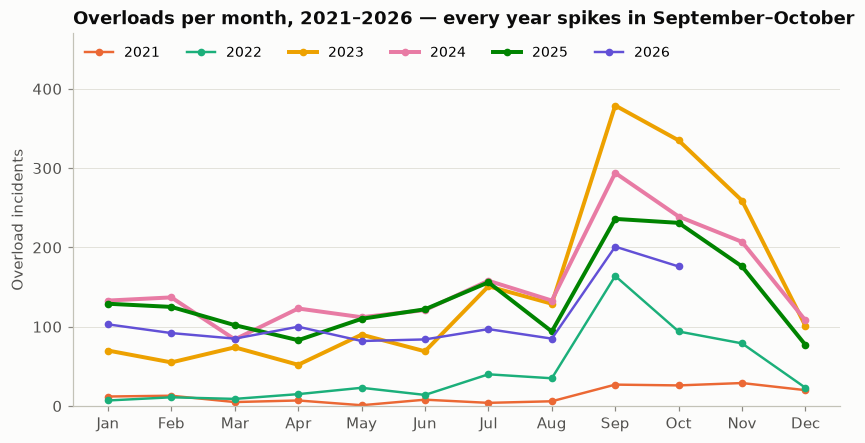

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2020,77,34,16,27,754,586,765,0,10,8,19,1
2021,12,13,5,7,1,8,4,6,27,26,29,20
2022,7,11,9,15,23,14,40,35,164,94,79,23
2023,70,55,74,52,90,69,151,129,379,335,259,101
2024,133,137,84,123,112,121,158,133,294,239,207,108
2025,129,125,102,83,110,122,156,94,236,231,176,77
2026,103,92,85,100,82,84,97,85,201,176,0,0


In [2]:
m = (ovl.assign(month=ovl.service_date.dt.month)
        .groupby(["year", "month"]).size().unstack(0).reindex(range(1, 13)))
# 2026 is partial: data ends 2026-10-30, so Nov/Dec are not zero but unknown
m.loc[11:, 2026] = np.nan

fig, ax = plt.subplots(figsize=(9, 4.4))
for y in [c for c in m.columns if c != 2020]:          # 2020 (COVID) shown separately in section 8
    ax.plot(m.index, m[y], marker="o", ms=4, color=SERIES[y - 2020], label=str(y),
            lw=2.6 if y in (2023, 2024, 2025) else 1.6)
ax.set_xticks(range(1, 13), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_ylabel("Overload incidents")
ax.set_title("Overloads per month, 2021–2026 — every year spikes in September–October")
ax.legend(ncol=6, loc="upper left", fontsize=9)
ax.set_ylim(0, 470)
save(fig, "01_overloads_per_month_by_year"); plt.show()
m.fillna(0).astype(int).T

## 2. Overloads by hour of day (Halifax time) and by weekday

saved C:\Users\user\Desktop\ML project\reports\figures\02_overloads_by_hour_weekday.png


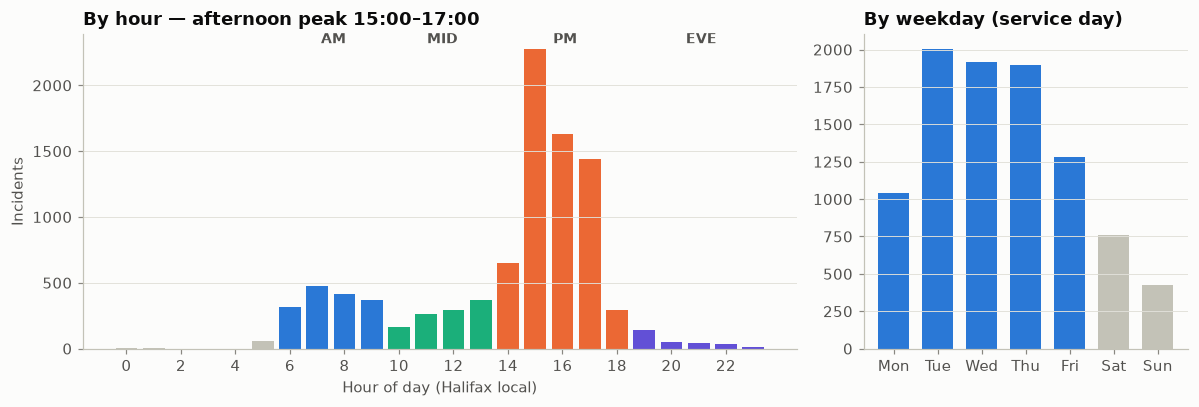

Share of incidents on weekends: 12.7%
Share outside 06–24 service hours: 0.8%


In [3]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
h = ovl.groupby("clock_hour").size().reindex(range(24), fill_value=0)
period_col = {**{k: SERIES[0] for k in range(6, 10)}, **{k: SERIES[2] for k in range(10, 14)},
              **{k: SERIES[1] for k in range(14, 19)}, **{k: SERIES[6] for k in range(19, 24)}}
a1.bar(h.index, h.values, width=0.8, color=[period_col.get(k, GRAY) for k in h.index])
for lab, x, c in [("AM", 8, SERIES[0]), ("MID", 12, SERIES[2]), ("PM", 16.5, SERIES[1]), ("EVE", 21.5, SERIES[6])]:
    a1.text(x - 0.4, h.max() * 1.02, lab, color=INK2, fontsize=9, ha="center", fontweight="bold")
a1.set_xticks(range(0, 24, 2)); a1.set_xlabel("Hour of day (Halifax local)"); a1.set_ylabel("Incidents")
a1.set_title("By hour — afternoon peak 15:00–17:00")
wd = ovl.groupby("weekday").size().reindex(range(7), fill_value=0)
a2.bar(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"], wd.values, width=0.7,
       color=[BLUE]*5 + [GRAY]*2)
a2.set_title("By weekday (service day)")
fig.tight_layout(); save(fig, "02_overloads_by_hour_weekday"); plt.show()
print("Share of incidents on weekends:", f"{(ovl.weekday >= 5).mean():.1%}")
print("Share outside 06–24 service hours:", f"{ovl.period.isna().mean():.1%}")

## 3. Top routes by overload count

saved C:\Users\user\Desktop\ML project\reports\figures\03_top_routes.png


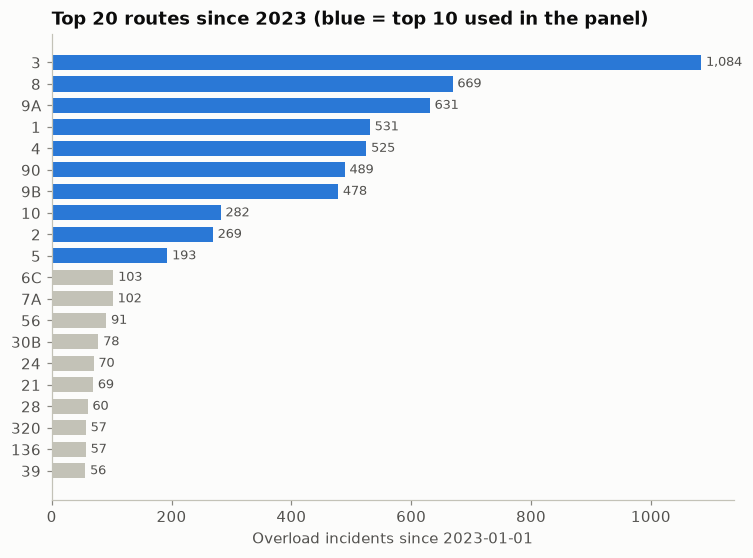

Top-10 share of all incidents since 2023: 81.0%


In [4]:
top_since = ovl[ovl.service_date >= "2023-01-01"].groupby("route_group").size().sort_values(ascending=False)
top10 = list(panel.route.cat.categories)
show = top_since.head(20)[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(show.index, show.values, height=0.7, color=[BLUE if r in top10 else GRAY for r in show.index])
for y, v in enumerate(show.values):
    ax.text(v + 8, y, f"{v:,}", va="center", fontsize=8.5, color=INK2)
ax.set_xlabel("Overload incidents since 2023-01-01")
ax.set_title("Top 20 routes since 2023 (blue = top 10 used in the panel)")
ax.grid(axis="y", visible=False)
save(fig, "03_top_routes"); plt.show()
print("Top-10 share of all incidents since 2023:", f"{top_since.head(10).sum() / top_since.sum():.1%}")

## 4. Where overloads happen

incidents outside the whole-network window: 55


saved C:\Users\user\Desktop\ML project\reports\figures\04_overload_locations.png


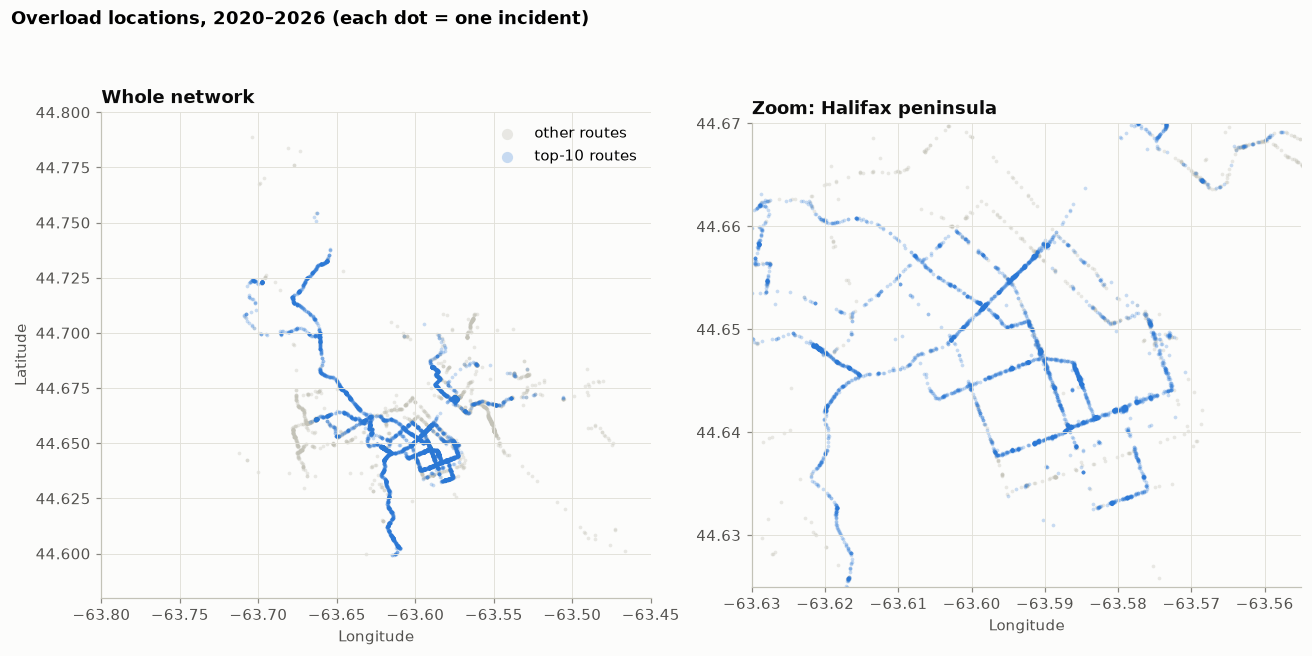

In [5]:
other = ovl[~ovl.route_group.isin(top10)]
top = ovl[ovl.route_group.isin(top10)]
fig, axes = plt.subplots(1, 2, figsize=(12, 6.2))
for ax, (xl, yl, ttl) in zip(axes, [((-63.80, -63.45), (44.58, 44.80), "Whole network"),
                                    ((-63.63, -63.555), (44.625, 44.67), "Zoom: Halifax peninsula")]):
    ax.scatter(other.lon, other.lat, s=6, alpha=0.35, color=GRAY, label="other routes", linewidths=0)
    ax.scatter(top.lon, top.lat, s=6, alpha=0.25, color=BLUE, label="top-10 routes", linewidths=0)
    ax.set_xlim(xl); ax.set_ylim(yl); ax.grid(True, axis="both")
    ax.set_aspect(1 / np.cos(np.deg2rad(44.65)))   # equal-distance aspect at Halifax latitude
    ax.set_xlabel("Longitude"); ax.set_title(ttl)
axes[0].set_ylabel("Latitude"); axes[0].legend(markerscale=3, loc="upper right")
fig.suptitle("Overload locations, 2020–2026 (each dot = one incident)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
print("incidents outside the whole-network window:",
      int((~ovl.lon.between(-63.80, -63.45) | ~ovl.lat.between(44.58, 44.80)).sum()))
save(fig, "04_overload_locations"); plt.show()

## 5. The modelling panel — class balance and positive rates

Panel = top 10 routes × non-holiday weekdays × {AM, MID, PM, EVE}, 2020-01 → 2026-10.
2020 is flagged (`is_covid`) and excluded from the rates below.

rows: 68,080 (excl. 2020: 58,040)
positives: 4,526 (6.65%);  excl. 2020: 3,836 (6.61%)
cells with >1 overload among positives: 21.8%


saved C:\Users\user\Desktop\ML project\reports\figures\05_positive_rate_period_route.png


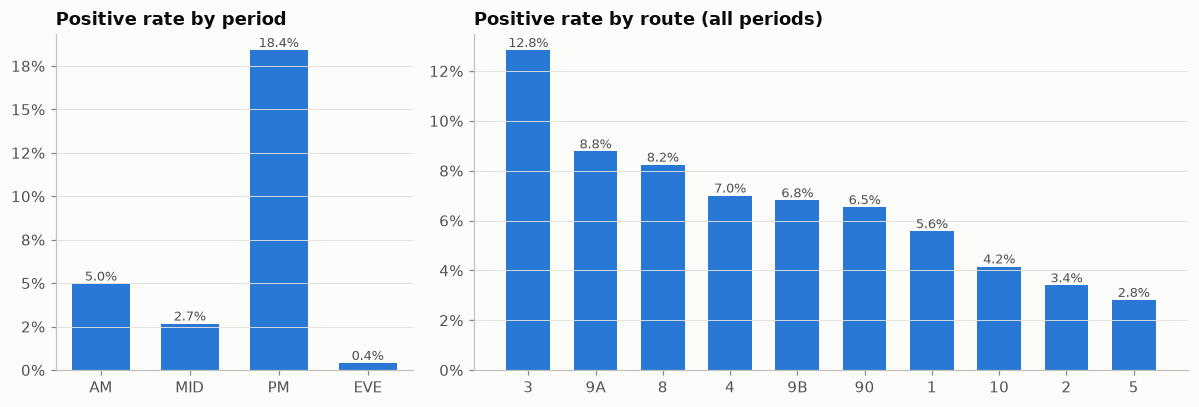

period,AM,MID,PM,EVE
route,,,,
3,16.6%,1.8%,32.6%,0.3%
8,3.6%,3.1%,26.0%,0.3%
9A,6.2%,3.4%,24.9%,0.5%
1,2.8%,2.2%,16.6%,0.7%
4,7.7%,4.3%,15.2%,0.7%
90,5.4%,2.8%,17.4%,0.5%
9B,2.2%,2.8%,22.1%,0.2%
10,2.8%,2.8%,10.6%,0.4%
2,1.2%,1.5%,10.5%,0.3%


In [6]:
p = panel[panel.is_covid == 0]
print(f"rows: {len(panel):,} (excl. 2020: {len(p):,})")
print(f"positives: {panel.y.sum():,} ({panel.y.mean():.2%});  excl. 2020: {p.y.sum():,} ({p.y.mean():.2%})")
print("cells with >1 overload among positives:", f"{(p[p.y == 1].n_overloads > 1).mean():.1%}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 2]})
pr = p.groupby("period", observed=True).y.mean()
a1.bar(pr.index.astype(str), pr.values, width=0.65, color=BLUE)
a1.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); a1.set_title("Positive rate by period")
for x, v in enumerate(pr.values): a1.text(x, v, f"{v:.1%}", ha="center", va="bottom", fontsize=8.5, color=INK2)
rr = p.groupby("route", observed=True).y.mean().sort_values(ascending=False)
a2.bar(rr.index.astype(str), rr.values, width=0.65, color=BLUE)
a2.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); a2.set_title("Positive rate by route (all periods)")
for x, v in enumerate(rr.values): a2.text(x, v, f"{v:.1%}", ha="center", va="bottom", fontsize=8.5, color=INK2)
fig.tight_layout(); save(fig, "05_positive_rate_period_route"); plt.show()

(p.pivot_table(index="route", columns="period", values="y", aggfunc="mean", observed=True)
   .mul(100).round(1).style.background_gradient(cmap="Blues", axis=None).format("{:.1f}%"))

## 6. Is there signal in lagged boardings?

Positive rate per decile of the past-only ridership features (2020 excluded).
Left: raw 4-week mean — mostly separates busy from quiet route-periods.
Right: the 1-week lag **relative to that route-period's own 2022+ median**, a check for signal *within* a route-period beyond its identity.

saved C:\Users\user\Desktop\ML project\reports\figures\06_overload_rate_vs_lagged_boardings.png


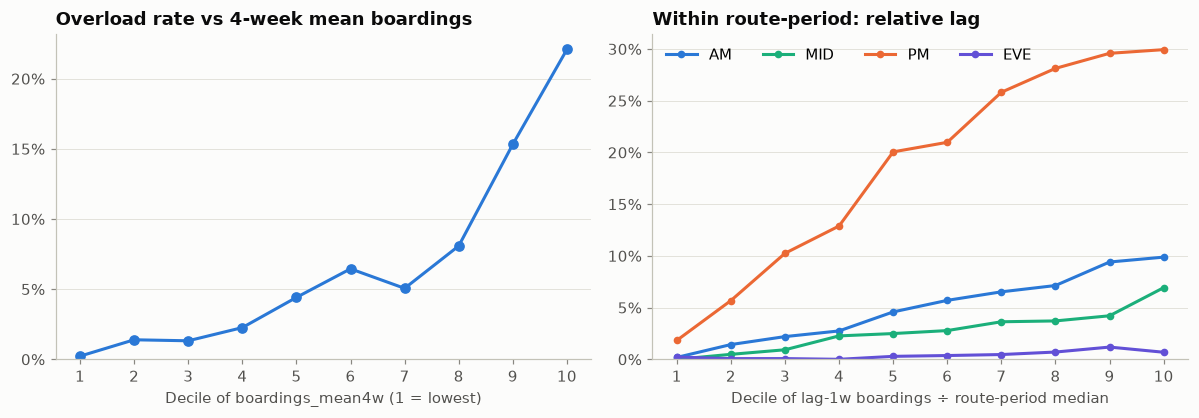

rate by decile (mean4w): {1: 0.2, 2: 1.4, 3: 1.3, 4: 2.3, 5: 4.4, 6: 6.4, 7: 5.1, 8: 8.1, 9: 15.3, 10: 22.1}
corr(rel_lag1w, y) by period: {'AM': 0.144, 'MID': 0.113, 'PM': 0.237, 'EVE': 0.041}


In [7]:
p = panel[(panel.is_covid == 0)].dropna(subset=["boardings_mean4w", "boardings_lag1w"]).copy()
p["dec_mean4w"] = pd.qcut(p.boardings_mean4w, 10, labels=False, duplicates="drop") + 1
med = p[p.year >= 2022].groupby(["route", "period"], observed=True).boardings_mean4w.median().rename("rp_median")
p = p.join(med, on=["route", "period"])
p["rel_lag1w"] = p.boardings_lag1w / p.rp_median
p["dec_rel"] = pd.qcut(p.rel_lag1w, 10, labels=False, duplicates="drop") + 1

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.9), sharey=False)
r1 = p.groupby("dec_mean4w").y.mean()
a1.plot(r1.index, r1.values, marker="o", color=BLUE)
a1.set_xlabel("Decile of boardings_mean4w (1 = lowest)"); a1.set_title("Overload rate vs 4-week mean boardings")
for i, per in enumerate(["AM", "MID", "PM", "EVE"]):
    s = p[p.period == per].groupby("dec_rel").y.mean()
    a2.plot(s.index, s.values, marker="o", ms=4, color=SERIES[[0, 2, 1, 6][i]], label=per)
a2.set_xlabel("Decile of lag-1w boardings ÷ route-period median"); a2.set_title("Within route-period: relative lag")
a2.legend(ncol=4)
for a in (a1, a2):
    a.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); a.set_xticks(range(1, 11)); a.set_ylim(0)
fig.tight_layout(); save(fig, "06_overload_rate_vs_lagged_boardings"); plt.show()
print("rate by decile (mean4w):", (r1 * 100).round(1).to_dict())
print("corr(rel_lag1w, y) by period:", p.groupby("period", observed=True)[["rel_lag1w", "y"]].corr().xs("y", level=1)["rel_lag1w"].round(3).to_dict())

## 7. Total APC boardings vs overloads, per month (all years)

Two panels on a shared time axis (not a dual axis). APC partial months (Oct 2017 start, Nov 2026) are marked.

saved C:\Users\user\Desktop\ML project\reports\figures\07_boardings_vs_overloads_monthly.png


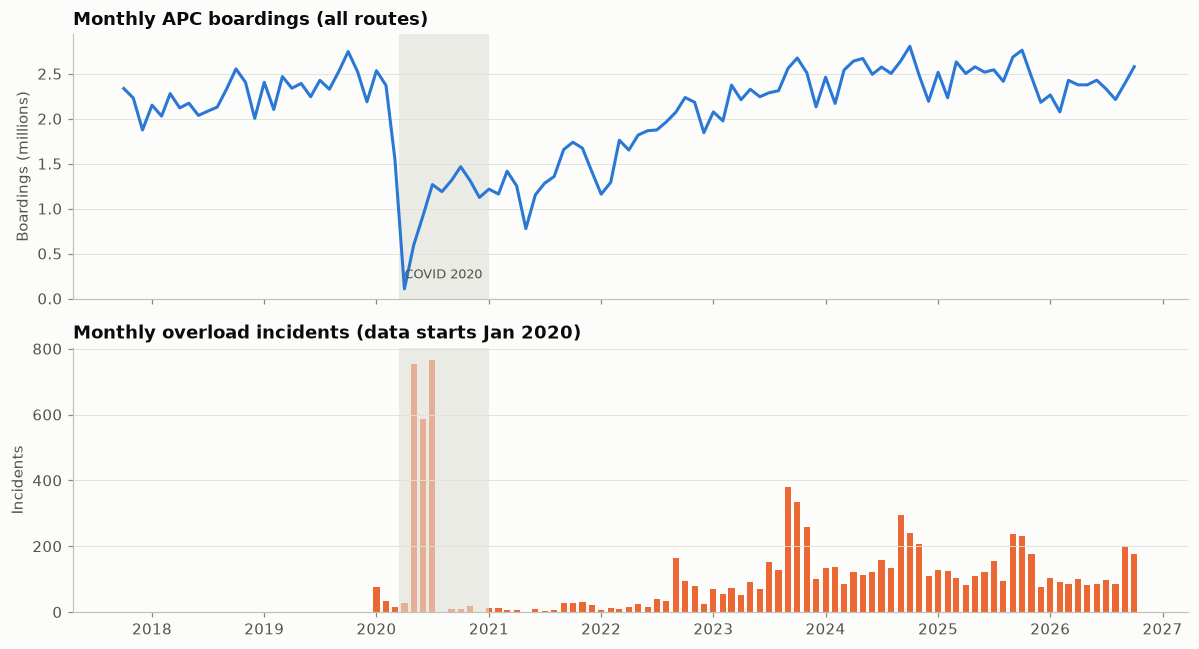

,apc_boardings_M,apc_days,overloads,overloads_per_M_boardings
year,,,,
2017,6.400000,92,NaN,NaN
2018,26.299999,365,NaN,NaN
2019,28.700001,365,NaN,NaN
2020,15.800000,365,2297.0,145.4
2021,16.100000,365,158.0,9.8
2022,21.700001,365,514.0,23.7
2023,27.700001,364,1764.0,63.7
2024,30.200001,366,1849.0,61.2
2025,30.000000,365,1641.0,54.7


In [8]:
b = apc.groupby(apc.service_date.dt.to_period("M")).ridership.sum() / 1e6
o = ovl.groupby(ovl.service_date.dt.to_period("M")).size()
idx = pd.period_range("2017-10", "2026-11", freq="M")
b, o = b.reindex(idx), o.reindex(idx)
o[(idx < pd.Period("2020-01", "M")) | (idx > pd.Period("2026-10", "M"))] = np.nan   # no overload data
days = apc.groupby(apc.service_date.dt.to_period("M")).service_date.nunique().reindex(idx)
b[days < 25] = np.nan                                                                # Nov 2026: 6 days only
x = idx.to_timestamp()

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [1, 1]})
a1.plot(x, b.values, color=BLUE)
a1.set_ylabel("Boardings (millions)"); a1.set_title("Monthly APC boardings (all routes)"); a1.set_ylim(0)
a2.bar(x, o.values, width=20, color=SERIES[1])
a2.set_ylabel("Incidents"); a2.set_title("Monthly overload incidents (data starts Jan 2020)")
for a in (a1, a2):
    a.axvspan(pd.Timestamp("2020-03-15"), pd.Timestamp("2020-12-31"), color=GRID, alpha=0.6, lw=0)
a1.text(pd.Timestamp("2020-04-01"), b.max() * 0.08, "COVID 2020", fontsize=8.5, color=INK2)
fig.tight_layout(); save(fig, "07_boardings_vs_overloads_monthly"); plt.show()

yr = pd.DataFrame({"apc_boardings_M": apc.groupby("year").ridership.sum() / 1e6,
                   "apc_days": apc.groupby("year").service_date.nunique(),
                   "overloads": ovl.groupby("year").size()}).round(1)
yr["overloads_per_M_boardings"] = (yr.overloads / yr.apc_boardings_M).round(1)
yr

## 8. 2020 in detail: are pre-COVID and COVID-era overloads different?

saved C:\Users\user\Desktop\ML project\reports\figures\08_overloads_2020_weekly.png


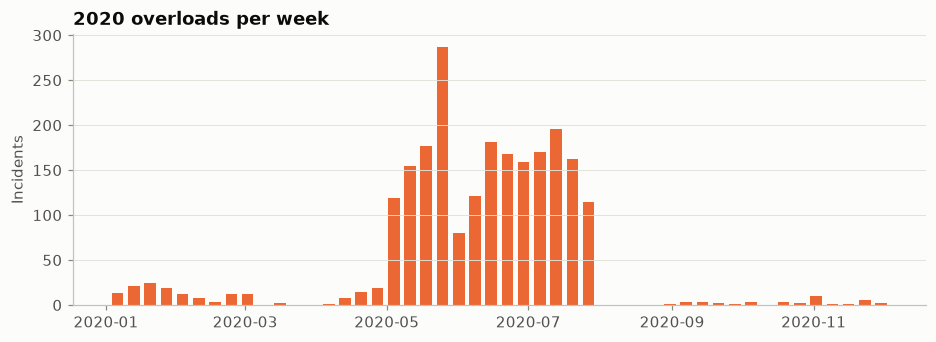

2020 incidents before 2020-03-15: 125  after: 2172


In [9]:
o20 = ovl[ovl.year == 2020]
w = o20.groupby(o20.service_date.dt.to_period("W")).size()
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(w.index.to_timestamp(), w.values, width=5, color=SERIES[1])
ax.set_title("2020 overloads per week"); ax.set_ylabel("Incidents")
save(fig, "08_overloads_2020_weekly"); plt.show()
print("2020 incidents before 2020-03-15:", (o20.service_date < "2020-03-15").sum(), " after:", (o20.service_date >= "2020-03-15").sum())

## 9. Data-quality checks

In [10]:
# APC coverage per year
cov = apc.groupby("year").agg(rows=("ridership_raw", "size"), dates=("service_date", "nunique"),
                              routes=("route", "nunique"), glitches_removed=("is_outlier", "sum"))
print(cov.to_string(), "\n")

# days where top-10 routes are missing APC data entirely (lag features NaN)
miss = panel[panel.boardings_lag1w.isna()].groupby("year").size()
print("panel rows with missing lag-1w boardings, by year:", miss.to_dict())

# APC daily totals: suspiciously low weekdays (partial data) since 2022
d = apc[apc.year >= 2022].groupby("service_date").ridership.sum()
d = d[d.index.dayofweek < 5]
roll = d.rolling(21, center=True, min_periods=5).median()
low = (d / roll)[(d / roll) < 0.5]
print("\nweekdays since 2022 with < 50% of local-median APC total (holidays + partial data):")
print(low.round(2).to_string())

# incidents on the top-10 routes that do not land in the panel
t = ovl[ovl.route_group.isin(top10)]
reason = np.select([t.weekday >= 5, ~t.service_date.isin(panel.date.unique()), t.period.isna()],
                   ["weekend", "holiday", "outside 06-24"], "in panel")
print("\ntop-10-route incidents by panel inclusion:", pd.Series(reason).value_counts().to_dict())

         rows  dates  routes  glitches_removed
year                                          
2017   229961     92      68                 0
2018   928652    365      75                22
2019   960003    365      74                 9
2020   961740    365      69                 2
2021  1007519    365      85                23
2022  1040324    365      79                15
2023  1011768    364      80                11
2024  1025799    366      80                30
2025  1054803    365      78                21
2026   893614    309      80                28 

panel rows with missing lag-1w boardings, by year: {2020: 666, 2021: 452, 2023: 40}



weekdays since 2022 with < 50% of local-median APC total (holidays + partial data):
service_date
2022-02-04    0.14
2022-02-21    0.40
2022-04-15    0.35
2022-05-23    0.44
2022-09-05    0.40
2022-10-10    0.32
2022-11-11    0.42
2022-12-26    0.34
2023-02-20    0.32
2023-04-07    0.43
2023-09-04    0.42
2023-10-09    0.35
2023-12-25    0.28
2023-12-26    0.37
2024-01-01    0.33
2024-01-29    0.47
2024-02-19    0.36
2024-03-29    0.36
2024-05-20    0.46
2024-07-01    0.41
2024-09-02    0.39
2024-10-14    0.25
2024-11-11    0.30
2024-12-25    0.23
2024-12-26    0.32
2025-01-01    0.27
2025-02-17    0.31
2025-04-18    0.43
2025-05-19    0.46
2025-09-01    0.42
2025-10-13    0.30
2025-11-11    0.37
2025-12-25    0.21
2025-12-26    0.31
2026-01-01    0.25
2026-01-26    0.35
2026-02-16    0.34
2026-04-03    0.33
2026-05-18    0.48
2026-08-03    0.46
2026-09-07    0.37
2026-10-12    0.27

top-10-route incidents by panel inclusion: {'in panel': 6057, 'weekend': 956, 'holiday': 114, 'outside 

## 10. Summary (first data round, 2026-11-08)

**Class balance.** The panel has **68,080** rows (10 routes × 1,702 non-holiday weekdays × 4 periods, 2020-01-02 → 2026-10-30)
with **4,526 positives (6.6%)**. Excluding 2020: 58,040 rows, 3,836 positives (6.6%).
It is strongly imbalanced *by period*: PM 18.4%, AM 5.0%, MID 2.7%, EVE 0.4%. By route it ranges from route 3 (12.8%) to route 5 (2.8%).
By year: 2021 1.0%, 2022 3.0%, 2023 8.8%, 2024 9.5%, 2025 9.6%, 2026 7.9% (to Oct).
About 22% of positive cells contain more than one incident (`n_overloads` is kept in case we want a count target).

**Usable APC data.** All files 2017–2026 have the **same schema** and are **half-hourly with direction** in every year; only the date format differs.
- 2017 covers only Oct–Dec.
- 2018–2026 are complete apart from 3 days with no APC data at all (2020-08-02, 2023-01-03, 2026-09-19). 2026 runs to 2026-11-06.
- 161 half-hour counter glitches (values of 500–7,900 at more than 5× the slot median) were set to NaN, removing 0.13% of boardings.
- Lag features are missing for 1.7% of panel rows, almost all route 5 MID/EVE in 2020–21 (see below).
- For modelling, **2022–2026** have clean APC data plus overloads under normal conditions. 2018–2019 are only useful as a ridership baseline (no overload data).

**Data-quality issues found / decisions taken.**
- **Time zone:** after UTC → Halifax conversion, incidents peak at 15:00–17:00 local, consistent with the afternoon peak. 13 after-midnight incidents were mapped to the previous service day.
- **Removed incidents:** 24 ferry incidents and 2 out-of-area points (lat 45.9).
- **Join quality:** 95.3% of incidents match an APC row on route + service date + exact half-hour, and about 100% within ±30 min. The misses are mostly 9A/9B, likely because APC credits boardings to the trip's start slot.
- **Route 10** split into 10A/10B/10C on 2024-11-18. These are **merged into "10"** (decision). No other overload route is used outside its APC years.
- **Route 5** changed from *Chebucto* (peak-only, low ridership) to *Portland* in Nov 2021. Pre-Nov-2021 rows are effectively a different route (this is the source of most missing lags). `route_name` is in the panel so these rows can be filtered.
- **Holidays:** the stat-only NS list misses Boxing Day, Thanksgiving, Victoria Day, Natal Day and Truth & Reconciliation Day. Ridership on these is 0.3–0.6× a normal weekday, so they are **treated as holidays** (decision): 81 weekday holidays are dropped and skipped in the lags. The 2022 Queen's funeral is in the library's list but ridership was 0.91× normal (one day, harmless).
- **Weather signal:** a few non-holiday weekdays have very low APC totals (2022-02-04 at 0.14×, 2024-01-29, 2026-01-26), probably storm days or service suspensions. Weather features should capture these.
- **Excluded by design:** 12.7% of incidents happen on weekends and 0.8% between 00:00 and 06:00. Of the top-10-route incidents, 6,057 land in the panel; 956 are on weekends, 114 on holidays and 51 between 00:00 and 06:00.

**Surprises.**
1. **2020 is a different regime.** 2,172 of its 2,297 incidents fall in **May–July 2020**, when COVID capacity limits made buses "full" at a few riders. There are almost none Aug–Dec 2020. Excluding 2020 (`is_covid`) is clearly right.
2. **Overloads per boarding jumped after 2022.** Incidents per million boardings: 9.8 (2021), 23.7 (2022), then 55–64 (2023–2025), even though ridership only returned to 2019 levels. This could be real crowding or a change in reporting practice. Training on 2023+ (or including `year`) is worth discussing.
3. **Tue–Thu have about twice the incidents of Mon and Fri**, and the September spike is visible every year, including 2022. Both point at university schedules, which supports adding the academic calendar.
4. **Lagged boardings carry clear signal.** The overload rate rises from 0.2% in the lowest decile of the 4-week mean to 22% in the top decile. *Within* a route-period, a busier-than-usual previous week raises the PM rate from about 2% to about 30%. So there is signal beyond route identity alone.